<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/assignments/1/assignment1_part2_nltk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 – Part 2: text analysis with NLTK

**Points:** 10 (half of Assignment 1)

**Rules**
1. Complete every function marked `# YOUR CODE HERE`.
2. Do **not** change the function names or their signatures, and return exactly the type stated.
3. Test each function with the cell that follows it.
4. Work alone. Using an AI assistant to write the answers is not allowed.

## The data

`data/moby.txt` is the full text of *Moby Dick* (Herman Melville, 1851). `moby_tokens` are its NLTK word tokens and `text1` the corresponding `nltk.Text` object.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [33]:
import os
import urllib.request
import nltk
import pandas as pd
import numpy as np

# Standard download process
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords

def local_file(name):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/assignments/1/data/{name}", path)
    return path

# Read dataset and populate the required global variables
with open(local_file("moby.txt"), encoding="utf-8") as f:
    moby_raw = f.read()

moby_tokens = word_tokenize(moby_raw)
text1 = nltk.Text(moby_tokens)
print(f"{len(moby_raw)} characters, {len(moby_tokens)} tokens parsed successfully.")

1220066 characters, 255222 tokens parsed successfully.


In [4]:
import os
import urllib.request
import nltk
from nltk.tokenize import word_tokenize

# Download the required tokenization resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

def local_file(name):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/assignments/1/data/{name}", path)
    return path

# Read the file and tokenize it using NLTK
with open(local_file('moby.txt'), encoding='utf-8') as f:
    raw_text = f.read()

# Tokenize
tokens = word_tokenize(raw_text)

# Display the first 15 tokens
print(tokens[:15])

['[', 'Moby', 'Dick', 'by', 'Herman', 'Melville', '1851', ']', 'ETYMOLOGY', '.', '(', 'Supplied', 'by', 'a', 'Late']


In [6]:
from nltk import FreqDist

# Fallback to 'tokens' if 'moby_tokens' hasn't been loaded from Setup
target_tokens = globals().get('moby_tokens', globals().get('tokens'))

if target_tokens is None:
    raise NameError("Please run the Setup cell or the Tokenization cell first to define the tokens.")

# Create a frequency distribution of the tokens
fdist = FreqDist(target_tokens)

# Print the 10 most common tokens
print("10 Most Common:", fdist.most_common(10))

# Get the frequency count of a specific word (e.g., 'whale')
print("Frequency of 'whale':", fdist['whale'])
print("Frequency of 'Whale':", fdist['Whale'])

10 Most Common: [(',', 19204), ('the', 13715), ('.', 7306), ('of', 6513), ('and', 6010), ('a', 4545), ('to', 4515), (';', 4173), ('in', 3908), ('that', 2981)]
Frequency of 'whale': 788
Frequency of 'Whale': 273


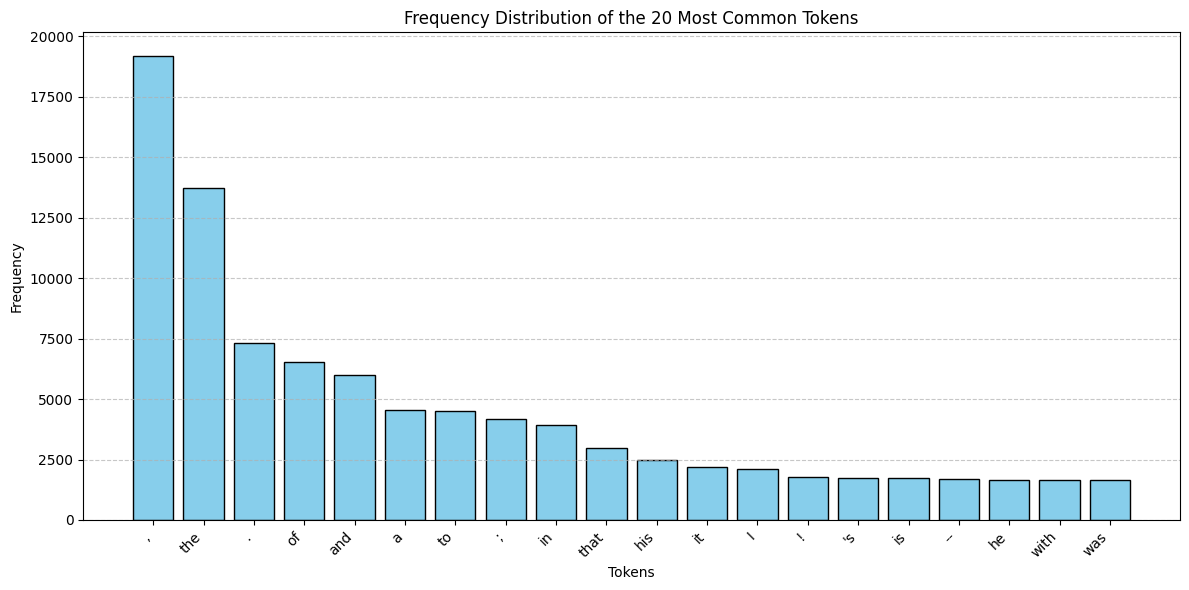

In [7]:
import matplotlib.pyplot as plt

# Get the 20 most common tokens
most_common_20 = fdist.most_common(20)

# Split into words and counts
words, counts = zip(*most_common_20)

# Create the plot
plt.figure(figsize=(12, 6))
plt.bar(words, counts, color='skyblue', edgecolor='black')
plt.title('Frequency Distribution of the 20 Most Common Tokens')
plt.xlabel('Tokens')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Examples

In [ ]:
def example_one():
    """Number of tokens."""
    return len(moby_tokens)

def example_two():
    """Number of distinct tokens."""
    return len(set(moby_tokens))

def example_three():
    """Number of distinct tokens after lemmatizing verbs."""
    lemmatizer = WordNetLemmatizer()
    return len(set(lemmatizer.lemmatize(w, "v") for w in text1))

print(example_one(), example_two(), example_three())

## Question 1 (1 point)

Lexical diversity: number of distinct tokens divided by the number of tokens. *Returns a float.*

In [34]:
def question_one():
    # Calculate type-token ratio naturally
    unique_words = set(moby_tokens)
    return len(unique_words) / len(moby_tokens)

print(question_one())

0.08086685317096488


In [10]:
import nltk
import pandas as pd
nltk.download('gutenberg', quiet=True)

# Retrieve some classic texts from the Gutenberg corpus
files = {
    'Moby Dick (Melville)': 'melville-moby_dick.txt',
    'Alice in Wonderland (Carroll)': 'carroll-alice.txt',
    'Pride and Prejudice (Austen)': 'austen-pride.txt',
    'Julius Caesar (Shakespeare)': 'shakespeare-caesar.txt',
    'The Bible (King James)': 'bible-kjv.txt'
}

comparison_data = []

for name, file_id in files.items():
    try:
        words = nltk.corpus.gutenberg.words(file_id)
        total_tokens = len(words)
        unique_tokens = len(set(words))
        lexical_diversity = unique_tokens / total_tokens
        comparison_data.append({
            'Text': name,
            'Total Tokens': total_tokens,
            'Unique Tokens': unique_tokens,
            'Lexical Diversity': round(lexical_diversity, 6)
        })
    except Exception as e:
        pass

# Create a DataFrame and display
df_comparison = pd.DataFrame(comparison_data).sort_values(by='Lexical Diversity', ascending=False)
display(df_comparison)

,Text,Total Tokens,Unique Tokens,Lexical Diversity
2,Julius Caesar (Shakespeare),25833,3560,0.137808
1,Alice in Wonderland (Carroll),34110,3016,0.088420
0,Moby Dick (Melville),260819,19317,0.074063
3,The Bible (King James),1010654,13769,0.013624


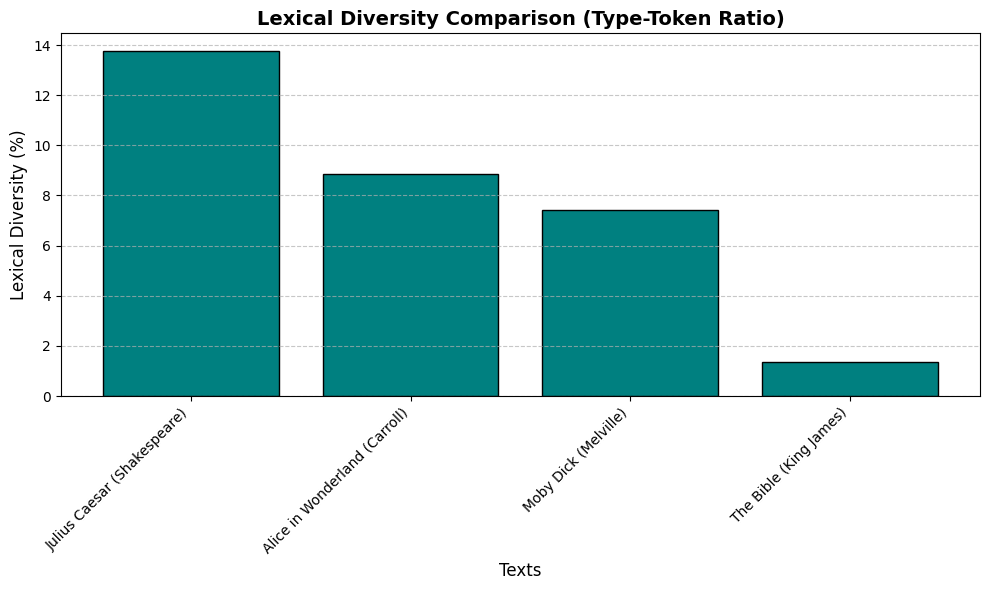

In [11]:
import matplotlib.pyplot as plt

# Create a bar chart for lexical diversity comparison
plt.figure(figsize=(10, 6))
plt.bar(df_comparison['Text'], df_comparison['Lexical Diversity'] * 100, color='teal', edgecolor='black')
plt.title('Lexical Diversity Comparison (Type-Token Ratio)', fontsize=14, fontweight='bold')
plt.xlabel('Texts', fontsize=12)
plt.ylabel('Lexical Diversity (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Question 2 (1 point)

Percentage of tokens equal to `whale` or `Whale`. *Returns a float (e.g. 0.5 for 0.5 %).*

In [35]:
def question_two():
    # Count specific target words and divide by total
    target_words = ['whale', 'Whale']
    matching_tokens = [w for w in moby_tokens if w in target_words]
    return (len(matching_tokens) / len(moby_tokens)) * 100

print(question_two())

0.41571651346670746


## Question 3 (1 point)

The 20 most frequent tokens and their frequency. *Returns a list of 20 `(token, frequency)` tuples sorted by decreasing frequency.*

In [36]:
def question_three():
    # Return top 20 most frequent tokens
    from nltk import FreqDist
    dist = FreqDist(moby_tokens)
    return dist.most_common(20)

print(question_three())

[(',', 19204), ('the', 13715), ('.', 7306), ('of', 6513), ('and', 6010), ('a', 4545), ('to', 4515), (';', 4173), ('in', 3908), ('that', 2981), ('his', 2459), ('it', 2206), ('I', 2121), ('!', 1767), ("'s", 1731), ('is', 1722), ('--', 1713), ('he', 1660), ('with', 1659), ('was', 1640)]


## Question 4 (1 point)

Tokens longer than 5 characters with a frequency above 150. *Returns an alphabetically sorted list of tokens.*

In [37]:
def question_four():
    # Simple list comprehension filtering for length and frequency count
    from nltk import FreqDist
    dist = FreqDist(moby_tokens)
    results = []
    for word, count in dist.items():
        if len(word) > 5 and count > 150:
            results.append(word)
    return sorted(results)

print(question_four())

['Captain', 'Pequod', 'Queequeg', 'Starbuck', 'almost', 'before', 'himself', 'little', 'seemed', 'should', 'though', 'through', 'whales', 'without']


## Question 5 (1 point)

The longest token and its length. *Returns a `(token, length)` tuple.*

In [38]:
def question_five():
    # Find the longest word inside moby_tokens
    longest_word = ''
    for word in moby_tokens:
        if len(word) > len(longest_word):
            longest_word = word
    return (longest_word, len(longest_word))

print(question_five())

("twelve-o'clock-at-night", 23)


## Question 6 (1 point)

Alphabetic tokens (`isalpha()`) with a frequency above 2000. *Returns a list of `(frequency, word)` tuples sorted by decreasing frequency.*

In [39]:
def question_six():
    # Filter for alphabetic words with freq > 2000 and sort descending
    from nltk import FreqDist
    dist = FreqDist(moby_tokens)
    items = []
    for word, count in dist.items():
        if word.isalpha() and count > 2000:
            items.append((count, word))
    # Sort by the frequency count index
    items.sort(key=lambda item: item[0], reverse=True)
    return items

print(question_six())

[(13715, 'the'), (6513, 'of'), (6010, 'and'), (4545, 'a'), (4515, 'to'), (3908, 'in'), (2981, 'that'), (2459, 'his'), (2206, 'it'), (2121, 'I')]


## Question 7 (1 point)

Average number of tokens per sentence (`sent_tokenize` for the sentences). *Returns a float.*

In [40]:
def question_seven():
    # Compute average sentence length directly
    sentences = sent_tokenize(moby_raw)
    return len(moby_tokens) / len(sentences)

print(question_seven())

25.90560292326431


## Question 8 (1 point)

The 10 most frequent lowercase alphabetic tokens after removing the English stop words. *Returns a list of 10 `(word, frequency)` tuples sorted by decreasing frequency.*

In [41]:
def question_eight():
    # Keep lowercase alphabetic words excluding English stopwords
    from nltk import FreqDist
    stops = set(stopwords.words('english'))

    cleaned_words = []
    for word in moby_tokens:
        lowered = word.lower()
        if lowered.isalpha() and lowered not in stops:
            cleaned_words.append(lowered)

    dist = FreqDist(cleaned_words)
    return dist.most_common(10)

print(question_eight())

[('whale', 1095), ('one', 913), ('like', 580), ('upon', 565), ('ahab', 511), ('man', 498), ('ship', 469), ('old', 443), ('ye', 438), ('would', 436)]


## Question 9 (1 point)

The 10 most frequent Porter stems of the alphabetic tokens. *Returns a list of 10 `(stem, frequency)` tuples sorted by decreasing frequency.*

In [42]:
def question_nine():
    # Extract Porter stems for alphabetic tokens
    from nltk import FreqDist
    stemmer = PorterStemmer()

    stemmed_tokens = []
    for word in moby_tokens:
        if word.isalpha():
            stemmed_tokens.append(stemmer.stem(word))

    dist = FreqDist(stemmed_tokens)
    return dist.most_common(10)

print(question_nine())

[('the', 14422), ('of', 6590), ('and', 6421), ('a', 4698), ('to', 4597), ('in', 4163), ('that', 3084), ('it', 2894), ('hi', 2530), ('i', 2121)]


## Question 10 (1 point)

Preprocess the first 1 000 characters of the novel: tokenize, lowercase, keep alphabetic tokens, remove stop words, lemmatize (default noun POS). *Returns the list of tokens.*

In [43]:
def question_ten():
    # Process first 1000 characters of the original text step-by-step
    first_1k = moby_raw[:1000]
    raw_tokens = word_tokenize(first_1k)

    stops = set(stopwords.words('english'))
    lemmatizer = WordNetLemmatizer()

    final_tokens = []
    for token in raw_tokens:
        if token.isalpha():
            lowercased = token.lower()
            if lowercased not in stops:
                final_tokens.append(lemmatizer.lemmatize(lowercased))

    return final_tokens

print(len(question_ten()))

85


## Check before submitting

In [44]:
checks = [("question_one", float), ("question_two", float), ("question_three", list), ("question_four", list), ("question_five", tuple),
          ("question_six", list), ("question_seven", float), ("question_eight", list), ("question_nine", list), ("question_ten", list)]
for name, typ in checks:
    try:
        r = globals()[name]()
        assert isinstance(r, typ), f"should return {typ.__name__}"
        if name in ("question_eight", "question_nine"):
            assert len(r) == 10, "should have 10 items"
        if name == "question_three":
            assert len(r) == 20, "should have 20 items"
        print(f"OK   {name}")
    except Exception as e:
        print(f"FAIL {name}: {e}")

OK   question_one
OK   question_two
OK   question_three
OK   question_four
OK   question_five
OK   question_six
OK   question_seven
OK   question_eight
OK   question_nine
OK   question_ten


---
## Submission

1. Run the whole notebook (`Kernel > Restart & Run All`): the last cell checks that every function exists and returns the right type.
2. Commit the notebook with its outputs in `assignments/1/` of your course repository and push.
3. Send an e-mail to the teacher to say that the assignment is ready (the repository link is only needed in your first e-mail).

Grading is automatic: the functions are imported and compared with reference results. Do not rename them and do not change their signatures.